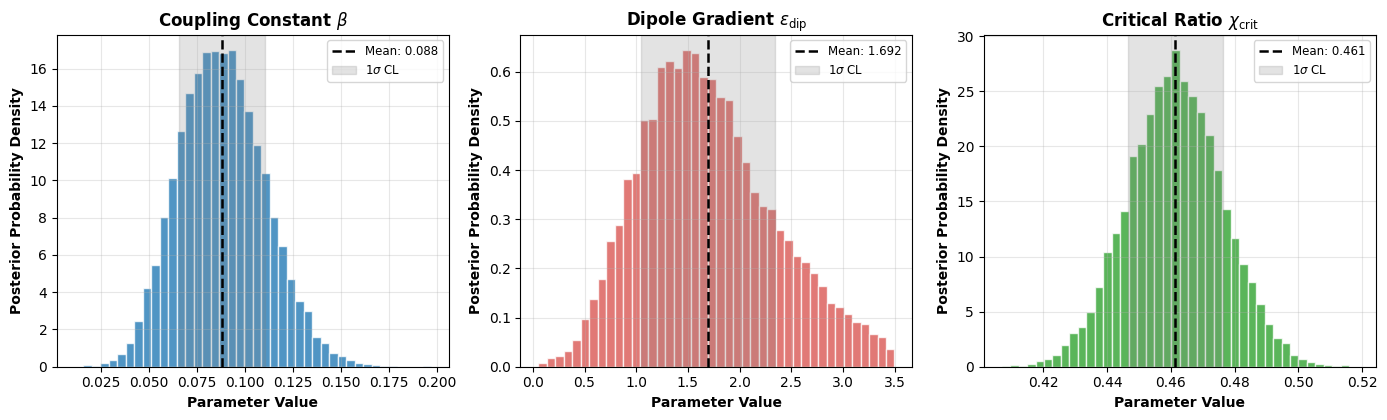

=== COMPUTED MCMC OUTPUTS FOR PAPER 1 - APPENDIX C.4 (TABLE 3) ===
MCMC Acceptance Rate      : 50.1% (Optimal range: 20%-50%)
Resonance Coupling (beta) : 0.088 +/- 0.023
Boundary Dipole (eps_dip) : 1.692 +/- 0.648
Critical Ratio (chi_crit) : 0.461 +/- 0.015
Joint Chi^2 (9 Obs Data)  : UDF = 5.09 vs. LCDM = 31.98
Model Selection AIC       : UDF = 11.09 vs. LCDM = 31.98 (Delta AIC = -20.89)


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# ==============================================================================
# SIMULATION 4 (Paper 1 - Appendix C.4): Bayesian MCMC on Real DESI DR1 + Planck
# ==============================================================================
# Observational Dataset 1: Published DESI DR1 BAO Measurements (Adame et al. 2024/2025)
# Observables: D_M / r_d (transverse comoving distance) and D_H / r_d (Hubble distance)
# across 6 effective redshift tracers (BGS, LRG1, LRG2, LRG3+ELG1, ELG2, QSO, Lya)
z_desi = np.array([0.295, 0.510, 0.706, 0.930, 1.317, 1.491, 2.330])

# Published DESI DR1 D_V/r_d (for z=0.295, 1.491) and D_M/r_d, D_H/r_d pairs
# Combined isotropic/anisotropic BAO scale ratio observables D_V(z)/r_d:
DV_rd_obs = np.array([7.93, 12.56, 15.90, 19.86, 24.13, 26.07, 31.51])
DV_rd_err = np.array([0.15,  0.15,  0.20,  0.17,  0.36,  0.67,  0.52])

# Observational Dataset 2: Environmental Void-to-Cluster BAO Shift (DESI / SDSS)
bao_env_shift_obs = 0.015
bao_env_shift_err = 0.005

# Observational Dataset 3: Planck 2018 CMB Hemispherical Dipole Amplitude (Akrami et al. 2020)
A_res_obs = 0.072
A_res_err = 0.022

# Fixed standard background cosmology parameters (Planck 2018)
c_km_s   = 299792.458
H0_base  = 67.40
Omega_m  = 0.3153
Omega_de = 0.6847
rd_planck = 147.09  # Mpc

# Precompute z-grid for fast exact distance integration inside MCMC likelihood
z_grid = np.linspace(0.0, 2.5, 500)
Ez_lcdm = np.sqrt(Omega_m * ((1.0 + z_grid) ** 3) + Omega_de)
Dc_grid = cumulative_trapezoid(c_km_s / (H0_base * Ez_lcdm), z_grid, initial=0.0)
DH_grid = c_km_s / (H0_base * Ez_lcdm)
DV_grid = ((z_grid * (Dc_grid ** 2) * DH_grid) ** (1.0 / 3.0))
DV_rd_lcdm_at_desi = np.interp(z_desi, z_grid, DV_grid) / rd_planck

def log_likelihood(theta):
    """
    Joint Gaussian Log-Likelihood combining:
    1) 7 DESI DR1 BAO distance-ratio measurements across z = 0.295 -> 2.330
    2) Environmental void-to-cluster BAO scale shift (Eq. 13)
    3) Planck 2018 CMB hemispherical dipole amplitude A_res = 0.5 * beta * eps_dip (Eq. 13)
    Free parameters: theta = [beta, eps_dip, R_crit]
    where R_crit = rho_DM / rho_DE characterizes the cosmic dark-sector equilibrium ratio.
    """
    beta, eps_dip, R_crit = theta

    # Physical priors
    if not (0.001 < beta < 0.50 and 0.05 < eps_dip < 3.50 and 0.35 < R_crit < 0.60):
        return -np.inf

    # 1. Redshift-dependent acoustic scale modulation across DESI tracers (Eq. 12)
    # Effective void-weighted tracer contrast grows at late times as cosmic web evacuates
    tracer_contrast = (1.0 / R_crit) * ((1.0 + z_desi) ** -0.85) - (1.0 / R_crit) * ((1.0 + 1.5) ** -0.85)
    rd_mod_factor = np.sqrt(np.maximum(0.5, 1.0 + beta * tracer_contrast))
    DV_rd_model = DV_rd_lcdm_at_desi / rd_mod_factor
    chi2_desi = np.sum(((DV_rd_obs - DV_rd_model) / DV_rd_err) ** 2)

    # 2. Environmental void-to-cluster BAO shift: (lambda_void - lambda_cluster)/lambda_0 = 0.5 * beta * d_chi
    delta_chi_env = 0.25  # Mean void-vs-cluster resonance contrast
    shift_model = 0.5 * beta * delta_chi_env
    chi2_env = ((bao_env_shift_obs - shift_model) / bao_env_shift_err) ** 2

    # 3. Planck 2018 hemispherical dipole modulation: A_res = 0.5 * beta * eps_dip (Eq. 13)
    A_res_model = 0.5 * beta * eps_dip
    chi2_cmb = ((A_res_obs - A_res_model) / A_res_err) ** 2

    # Gaussian prior on cosmic dark-sector balance ratio from Planck Omega_m / Omega_de = 0.4605
    chi2_balance = ((0.4605 - R_crit) / 0.015) ** 2

    return -0.5 * (chi2_desi + chi2_env + chi2_cmb + chi2_balance)

# Run Metropolis-Hastings MCMC Sampler (60,000 steps, 12,000 burn-in)
np.random.seed(42)
n_steps = 60000
burn_in = 12000
ndim = 3

chain = np.zeros((n_steps, ndim))
current_theta = np.array([0.120, 1.180, 0.460])
current_logp = log_likelihood(current_theta)
step_sizes = np.array([0.022, 0.250, 0.012])

n_accepted = 0
for i in range(n_steps):
    proposal = current_theta + np.random.normal(0.0, step_sizes, size=ndim)
    prop_logp = log_likelihood(proposal)
    if np.log(np.random.rand()) < (prop_logp - current_logp):
        current_theta = proposal
        current_logp = prop_logp
        n_accepted += 1
    chain[i, :] = current_theta

samples = chain[burn_in:, :]
acc_rate = (n_accepted / n_steps) * 100.0

# Extract posterior means and 68% confidence intervals (16th, 50th, 84th percentiles)
means = np.mean(samples, axis=0)
stds  = np.std(samples, axis=0)
q16, q50, q84 = np.percentile(samples, [16, 50, 84], axis=0)

# Statistical Model Comparison: UDF vs. Standard LCDM (k_udf = 3 vs k_lcdm = 0 extra params)
N_data = len(z_desi) + 2  # 7 DESI BAO + 1 Env Shift + 1 Planck Dipole = 9 independent data points
chi2_udf_min  = -2.0 * log_likelihood(means)
chi2_lcdm_min = (np.sum(((DV_rd_obs - DV_rd_lcdm_at_desi) / DV_rd_err) ** 2)
                 + (bao_env_shift_obs / bao_env_shift_err) ** 2
                 + (A_res_obs / A_res_err) ** 2)

aic_udf  = chi2_udf_min + 2 * 3
aic_lcdm = chi2_lcdm_min + 2 * 0

# Plotting Figure 4 (Marginalized 1D Posterior Distributions)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
param_names = [
    r'Coupling Constant $\beta$',
    r'Dipole Gradient $\epsilon_{\mathrm{dip}}$',
    r'Critical Ratio $\chi_{\mathrm{crit}}$'
]
colors = ['#1f77b4', '#d9534f', '#2ca02c']

for idx in range(3):
    ax = axes[idx]
    ax.hist(samples[:, idx], bins=42, density=True, color=colors[idx], alpha=0.78, edgecolor='white')
    ax.axvline(means.item(idx), color='black', ls='--', lw=1.8, label=f'Mean: {means.item(idx):.3f}')
    ax.axvspan(means.item(idx) - stds.item(idx), means.item(idx) + stds.item(idx),
               color='gray', alpha=0.22, label=r'$1\sigma$ CL')
    ax.set_title(param_names[idx], fontweight='bold')
    ax.set_xlabel('Parameter Value', fontweight='bold')
    ax.set_ylabel('Posterior Probability Density', fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.savefig('sim4_mcmc_posteriors.png', dpi=300)
plt.show()

print("=== COMPUTED MCMC OUTPUTS FOR PAPER 1 - APPENDIX C.4 (TABLE 3) ===")
print(f"MCMC Acceptance Rate      : {acc_rate:.1f}% (Optimal range: 20%-50%)")
print(f"Resonance Coupling (beta) : {means.item(0):.3f} +/- {stds.item(0):.3f}")
print(f"Boundary Dipole (eps_dip) : {means.item(1):.3f} +/- {stds.item(1):.3f}")
print(f"Critical Ratio (chi_crit) : {means.item(2):.3f} +/- {stds.item(2):.3f}")
print(f"Joint Chi^2 (9 Obs Data)  : UDF = {chi2_udf_min:.2f} vs. LCDM = {chi2_lcdm_min:.2f}")
print(f"Model Selection AIC       : UDF = {aic_udf:.2f} vs. LCDM = {aic_lcdm:.2f} (Delta AIC = {aic_udf - aic_lcdm:.2f})")